# Paths

You will build: a trail map with a winding route and an arrow at its end, and a pie chart drawn with arcs.

Run it from this folder with ``python paths.py``, or open ``paths.ipynb``.

In [1]:
import math

import svgwriter as svg

A map background: grass, a lake and a few trees.

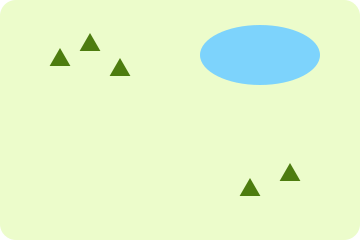

In [2]:
WIDTH, HEIGHT = 360, 240
FONT = "Arial, Helvetica, sans-serif"
trail = svg.Document(WIDTH, HEIGHT)
trail.rect(0, 0, WIDTH, HEIGHT, rx=16, fill="#ecfccb")
trail.ellipse(260, 55, 60, 30, fill="#7dd3fc")
for x, y in ((60, 60), (90, 45), (120, 70), (250, 190), (290, 175)):
    trail.add(svg.paths.regular_polygon(x, y, 12, 3, fill="#4d7c0f"))
trail

`svg.PathBuilder` draws a path step by step: move to the start, then curve from point to point.

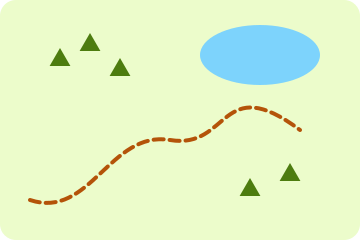

In [3]:
route = (
    svg.PathBuilder()
    .move_to(30, 200)
    .curve_to(90, 220, 110, 130, 170, 140)
    .smooth_curve_to(220, 70, 300, 130)
)
path = trail.path(route, fill="none", stroke="#b45309", stroke_width=4, stroke_dasharray="10 6",
                  stroke_linecap="round")
trail

A marker puts a shape on the ends of a line: an arrow head shows where the route goes.

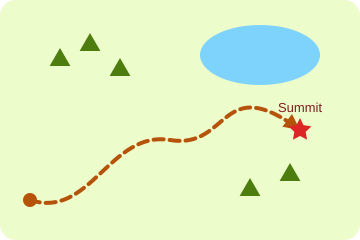

In [4]:
path.marker_end = svg.markers.arrow(4, color="#b45309")
trail.circle(30, 200, 7, fill="#b45309")
trail.add(svg.paths.star(300, 130, 12, points=5, fill="#dc2626"))
trail.text("Summit", x=300, y=112, font_size=13, text_anchor="middle", font_family=FONT, fill="#7f1d1d")
trail

## A pie chart

A slice is a line out from the centre, an arc along the rim and a line back. `arc_to` draws the arc.

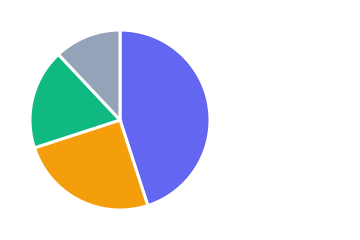

In [5]:
SHARES = {"Rent": (0.45, "#6366f1"), "Food": (0.25, "#f59e0b"), "Travel": (0.18, "#10b981"),
          "Other": (0.12, "#94a3b8")}
CX, CY, R = 120, 120, 90


def rim(fraction: float) -> tuple[float, float]:
    """The point on the rim a *fraction* of the way round, starting at the top."""
    angle = 2 * math.pi * fraction - math.pi / 2
    return CX + R * math.cos(angle), CY + R * math.sin(angle)


pie = svg.Document(360, 240)
pie.rect(0, 0, 360, 240, rx=16, fill="white")
start = 0.0
for share, color in SHARES.values():
    slice_ = svg.PathBuilder().move_to(CX, CY).line_to(*rim(start))
    slice_.arc_to(R, R, 0, share > 0.5, True, *rim(start + share)).close()
    pie.path(slice_, fill=color, stroke="white", stroke_width=3)
    start += share
pie

A legend finishes the chart.

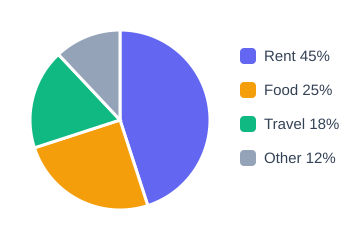

In [6]:
for row, (name, (share, color)) in enumerate(SHARES.items()):
    y = 60 + row * 34
    pie.rect(240, y - 12, 16, 16, rx=4, fill=color)
    pie.text(f"{name}  {share:.0%}", x=264, y=y + 1, font_size=15, font_family=FONT, fill="#334155")
pie

Save both. Next: [05 Booleans](../05_booleans/booleans.py) combines shapes into new ones.

In [7]:
trail.save("04_trail.svg")
pie.save("04_pie.svg")